# H15 Part A · Step 7, prepared · The nuScenes keyframes the side-car will be read on

Step 7 of [the plan](../../../docs/drivejepa-perception-sidecar-A.md) (§8.2) reads the side-car on
nuScenes, which neither it nor the released model ever saw. This notebook reviews the **prepared data**:

1. the scene draw, committed once;
2. the keyframes the pass kept, and why some were not;
3. the camera: the projection check, and NAVSIM's camera beside nuScenes';
4. the labels, the targets they make, and how they differ from NAVSIM's;
5. keyframes with their targets drawn through the side-car's own projection;
6. what is ready, and what step 7 still does.

It reads data only (the extract, the pass's labels and geometry, and images), **never a model**: no
nuScenes number about the side-car exists before step 7.

**Kernel:** `drive-jepa-v2` ("Drive-JEPA v2") at this site: it starts the interpreter `gallops.toml` names as
`[python] drivejepa` (Python 3.9, torch 2.1). Not `python3` ("Python 3 (ipykernel)"), which starts the system
Python without torch, and not `drive-jepa-py39`, another venv with another navsim tree first on its path.
Elsewhere, any kernel that starts `[python] drivejepa`. Headless: `scripts/run_notebooks.py`.

In [1]:
import json
import os
import pickle
import sys
import warnings
from pathlib import Path

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "gallops").is_dir())
sys.path.insert(0, str(REPO / "src"))
os.environ.setdefault("GALLOPS_CONFIG", str(REPO / "gallops.toml"))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Polygon
from matplotlib.ticker import FuncFormatter

from gallops.config import SiteConfig
from gallops.drivejepa_perception import navsim_data, ood, views
from gallops.drivejepa_perception import nuscenes_data as nd
from gallops.drivejepa_perception import targets as tg

views.use_style()
pd.set_option("display.precision", 3)
cfg = SiteConfig.load()
RUNS = Path(cfg.resolve("{runs}")) / "drivejepa_perception"
NUSC = Path(cfg.resolve("{data.nuscenes}"))
NAVSIM = Path(cfg.resolve("{data.navsim}"))
with open(RUNS / "nusc-extract" / "extract.pkl", "rb") as fh:
    extract = pickle.load(fh)
labels = dict(np.load(RUNS / "nusc-v1" / "labels.npz"))
outputs = np.load(RUNS / "nusc-v1" / "outputs.npz")
built, scene_of_row = outputs["built"], outputs["scene"]
lidar2img = outputs["lidar2img"]
manifest = json.loads((RUNS / "nusc-v1" / "manifest.json").read_text())
record = json.loads((REPO / "recipes" / "drivejepa_perception" / "ood_scenes.json").read_text())
ticks = ood.ood_ticks(extract)
assert len(ticks) == len(labels["sample"]) == manifest["rows"]
assert [t["sample"] for t in ticks] == labels["sample"].tolist()
proj = (tg.to_512(*ood.NUSC_SIZE) @ lidar2img[:, tg.FRONT_SLOT].astype(np.float64)).astype(np.float32)
print(f"{manifest['scenes']} scenes, {manifest['rows']:,} keyframes, {manifest['built']:,} built by the pass; "
      f"{manifest['agents']:,} labelled agents")


def targets_of(row):
    return tg.build(navsim_data.agents_of(labels, row), proj[row])


def y_axis_left(ax):
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{-v:g}"))
    ax.set_xlabel("y (m): + left, − right")
    ax.set_ylabel("x (m), forward")

100 scenes, 2,917 keyframes, 2,917 built by the pass; 82,718 labelled agents


## 1. The scene draw

Committed once in `recipes/drivejepa_perception/ood_scenes.json` and re-drawn from its own rule by every
reader, which refuses an edited list (`nuscenes_data.load_scenes`). Candidates are nuScenes **train**
scenes (val is paddock's benchmark) with CAN-bus poses, without any scene behind a neuroNCAP scenario or a
reconstructed one. The official split comes from the nuScenes devkit and the neuroNCAP scenes from
paddock's harness, each imported in the interpreter that has it (the record's `sources`).

In [2]:
sources = record["sources"]
pd.Series({
    "train scenes in the devkit's split": sources["train_scenes"]["train_scenes"],
    "with CAN-bus poses": sources["readable"],
    "candidates (neuroNCAP and reconstructed kept out)": len(record["candidates"]),
    "drawn (n, seed)": f"{record['n']} (seed {record['seed']})",
    "devkit": sources["train_scenes"]["devkit"],
    "paddock commit": sources["paddock_commit"][:7],
    "kept out, by number": ", ".join(sources["kept_out"]),
}, name="the draw").to_frame()

,the draw
train scenes in the devkit's split,700
with CAN-bus poses,685
candidates (neuroNCAP and reconstructed kept out),679
"drawn (n, seed)",100 (seed 0)
devkit,1.1.11
paddock commit,a1dd55e
"kept out, by number","0053, 0058, 0061, 0064, 0070, 0075, 0099, 0101..."


In [3]:
assert nd.load_scenes() == record["scenes"]
scenes = extract["scenes"]
desc = {name: s["description"].lower() for name, s in scenes.items()}
draw_table = pd.DataFrame({
    "location": [scenes[n]["location"] for n in record["scenes"]],
    "night": ["night" in desc[n] for n in record["scenes"]],
    "rain": ["rain" in desc[n] for n in record["scenes"]],
}, index=record["scenes"])
pd.concat({
    "scenes": draw_table.groupby("location").size(),
    "night": draw_table.groupby("location").night.sum(),
    "rain": draw_table.groupby("location").rain.sum(),
}, axis=1)

,scenes,night,rain
location,,,
boston-seaport,64,0,21
singapore-hollandvillage,10,6,0
singapore-onenorth,17,0,0
singapore-queenstown,9,5,0


## 2. The keyframes

A keyframe is kept (`nuscenes_data.ticks`) when the keyframe 0.5 s back exists (the model reads that
frame) and 4 s of future keyframes exist (the plan is read against them). nuScenes keyframes are 2 Hz, so
a 20 s scene gives about 40, of which the first and the last eight cannot be kept.

In [4]:
per_scene = pd.Series({n: sum(t["scene"] == n for t in ticks) for n in record["scenes"]})
keyframes = pd.Series({n: len(scenes[n]["keyframes"]) for n in record["scenes"]})
speed = np.array([t["speed"] for t in ticks])
pd.Series({
    "keyframes in the drawn scenes": int(keyframes.sum()),
    "kept by the tick rule": int(per_scene.sum()),
    "kept per scene: min, median, max": f"{per_scene.min()}, {int(per_scene.median())}, {per_scene.max()}",
    "built by the pass (inputs complete)": int(built.sum()),
    "ego speed (CAN bus): median, m/s": float(np.median(speed)),
    "ego stopped (< 0.5 m/s)": float((speed < 0.5).mean()),
}, name="keyframes").to_frame()

,keyframes
keyframes in the drawn scenes,4019
kept by the tick rule,2917
"kept per scene: min, median, max","23, 30, 31"
built by the pass (inputs complete),2917
"ego speed (CAN bus): median, m/s",5.412
ego stopped (< 0.5 m/s),0.217


## 3. The camera

**The projection check.** Before writing a scene's first row, the pass held the vendor's projection
(`lidar2img` × `to_512(1600, 900)`) to the one built straight from the scene's calibration (intrinsics,
camera pose, the 28-row crop, the resize) on a grid of points ahead; it would have stopped on a gap over
0.5 px. The largest gap over every scene:

In [5]:
print(f"largest projection gap over {manifest['scenes']} scenes: {manifest['projection_gap_px_max']:.2e} px (limit {ood.PROJECTION_LIMIT_PX})")
nav_row = 0  # any NAVSIM sample: its CAM_F0 calibration is shared across vehicles to a few mm
nav_proj = tg.front_projection(np.asarray(np.load(RUNS / "tokens-v1" / "lidar2img.npy", mmap_mode="r")[nav_row]))


def describe_camera(p):
    """The camera's centre, and its horizontal field of view between the image's left and right edges
    (both measured: nuScenes' principal point is not at the image's centre)."""
    centre, _ = views.camera_ray(p, 256.0, 128.0)
    edges = views.view_edges(p, reach=1.0)
    left, right = (np.arctan2(edges[k, 1] - edges[0, 1], edges[k, 0] - edges[0, 0]) for k in (1, 2))
    return {"camera centre x, y, z (m)": tuple(float(v) for v in np.round(centre, 2)),
            "horizontal field of view (°)": round(float(np.degrees(left - right)), 1),
            "left / right half-angle (°)": f"{np.degrees(left):.1f} / {-np.degrees(right):.1f}"}


pd.DataFrame({"NAVSIM CAM_F0": describe_camera(nav_proj), "nuScenes CAM_FRONT (first kept keyframe)": describe_camera(proj[0].astype(np.float64))})

largest projection gap over 100 scenes: 1.41e-05 px (limit 0.5)


,NAVSIM CAM_F0,nuScenes CAM_FRONT (first kept keyframe)
"camera centre x, y, z (m)","(1.67, -0.03, 1.52)","(1.7, 0.02, 1.51)"
horizontal field of view (°),63.7,64.5
left / right half-angle (°),32.0 / 31.7,33.1 / 31.4


## 4. The labels, and the targets they make

`ood.keyframe_agents` reads each keyframe's annotations into H15's label layout. nuScenes categories map to
the side-car's classes as below; only annotations at least one lidar point hit are kept (nuScenes'
detection convention: no sensor saw the rest). The targets then follow the same rule as on NAVSIM
(`targets.build`): the three classes, within 50 m, centre inside the 512×256 image, nearest 64.

In [6]:
pd.DataFrame([(prefix + "*", navsim_data.CLASSES[c]) for prefix, c in ood.CATEGORY_CLASS],
             columns=["nuScenes category", "H15 class"]).set_index("nuScenes category").T

nuScenes category,vehicle.bicycle*,vehicle.motorcycle*,vehicle.*,human.pedestrian.*,movable_object.barrier*,movable_object.trafficcone*
H15 class,cyclist,cyclist,vehicle,pedestrian,static,static


In [7]:
rows = np.flatnonzero(built)
nav_labels = dict(np.load(RUNS / "labels-v1" / "labels.npz"))
nav_logs = json.loads((RUNS / "labels-v1" / "manifest.json").read_text())["logs"]
nav_token_logs = np.array([nav_logs[i] for i in nav_labels["log_id"]])
splits = json.loads((REPO / "recipes" / "drivejepa_perception" / "splits.json").read_text())
nav_report = np.flatnonzero(np.isin(nav_token_logs, splits["report"]))
nav_proj_all = tg.front_projection(np.asarray(np.load(RUNS / "tokens-v1" / "lidar2img.npy", mmap_mode="r")))


def target_stats(rows_, labels_, proj_):
    per_sample, cls, rng, spd, ok = [], [], [], [], []
    for r in rows_:
        t = tg.build(navsim_data.agents_of(labels_, r), proj_[r])
        m = t["mask"]
        per_sample.append(int(m.sum()))
        cls.append(t["cls"][m])
        rng.append(np.hypot(t["box"][m, 0], t["box"][m, 1]))
        spd.append(np.hypot(*t["vel"][m].T))
        ok.append(t["path_ok"][m])
    cls, rng, spd, ok = map(np.concatenate, (cls, rng, spd, ok))
    per_sample = np.array(per_sample)
    return {
        "samples": len(rows_),
        "targets": int(len(cls)),
        "targets per sample: mean, median": f"{per_sample.mean():.2f}, {int(np.median(per_sample))}",
        "samples with no target": float((per_sample == 0).mean()),
        "vehicle, pedestrian, cyclist shares": ", ".join(f"{(cls == c).mean():.3f}" for c in range(3)),
        "within 30 m": float((rng < 30).mean()),
        "range 0–20, 20–30, 30–50 m": ", ".join(f"{v:.3f}" for v in ((rng < 20).mean(), ((rng >= 20) & (rng < 30)).mean(), (rng >= 30).mean())),
        "moving (> 1 m/s)": float((spd > 1).mean()),
        "path known at +0.5 s, +1.0 s": ", ".join(f"{v:.3f}" for v in ok.mean(0)),
    }


pd.DataFrame({"nuScenes, the drawn scenes": target_stats(rows, labels, proj),
              "NAVSIM, report logs (notebook 01)": target_stats(nav_report, nav_labels, nav_proj_all)})

,"nuScenes, the drawn scenes","NAVSIM, report logs (notebook 01)"
samples,2917,4636
targets,11136,24216
"targets per sample: mean, median","3.82, 3","5.22, 4"
samples with no target,0.129,0.182
"vehicle, pedestrian, cyclist shares","0.695, 0.283, 0.023","0.647, 0.346, 0.007"
within 30 m,0.474,0.41
"range 0–20, 20–30, 30–50 m","0.186, 0.288, 0.526","0.167, 0.243, 0.590"
moving (> 1 m/s),0.365,0.436
"path known at +0.5 s, +1.0 s","0.997, 0.995","0.986, 0.972"


**Reading it.** Two differences matter for step 7. nuScenes keeps only boxes some lidar point hit, so its
targets are, on average, more visible than NAVSIM's (which keep hidden agents too, notebook 01 §7). And the
class mix and range mix differ, so step 7 reports per class and per range, as step 6 does.

## 5. Keyframes, with their targets drawn through the side-car's projection

Six keyframes (seeded), from different locations. The boxes are the labels, projected through exactly the
matrix the side-car's rays will come from (`to_512(1600, 900)` × the pass's `lidar2img`). If the geometry
were wrong they would not sit on the agents.

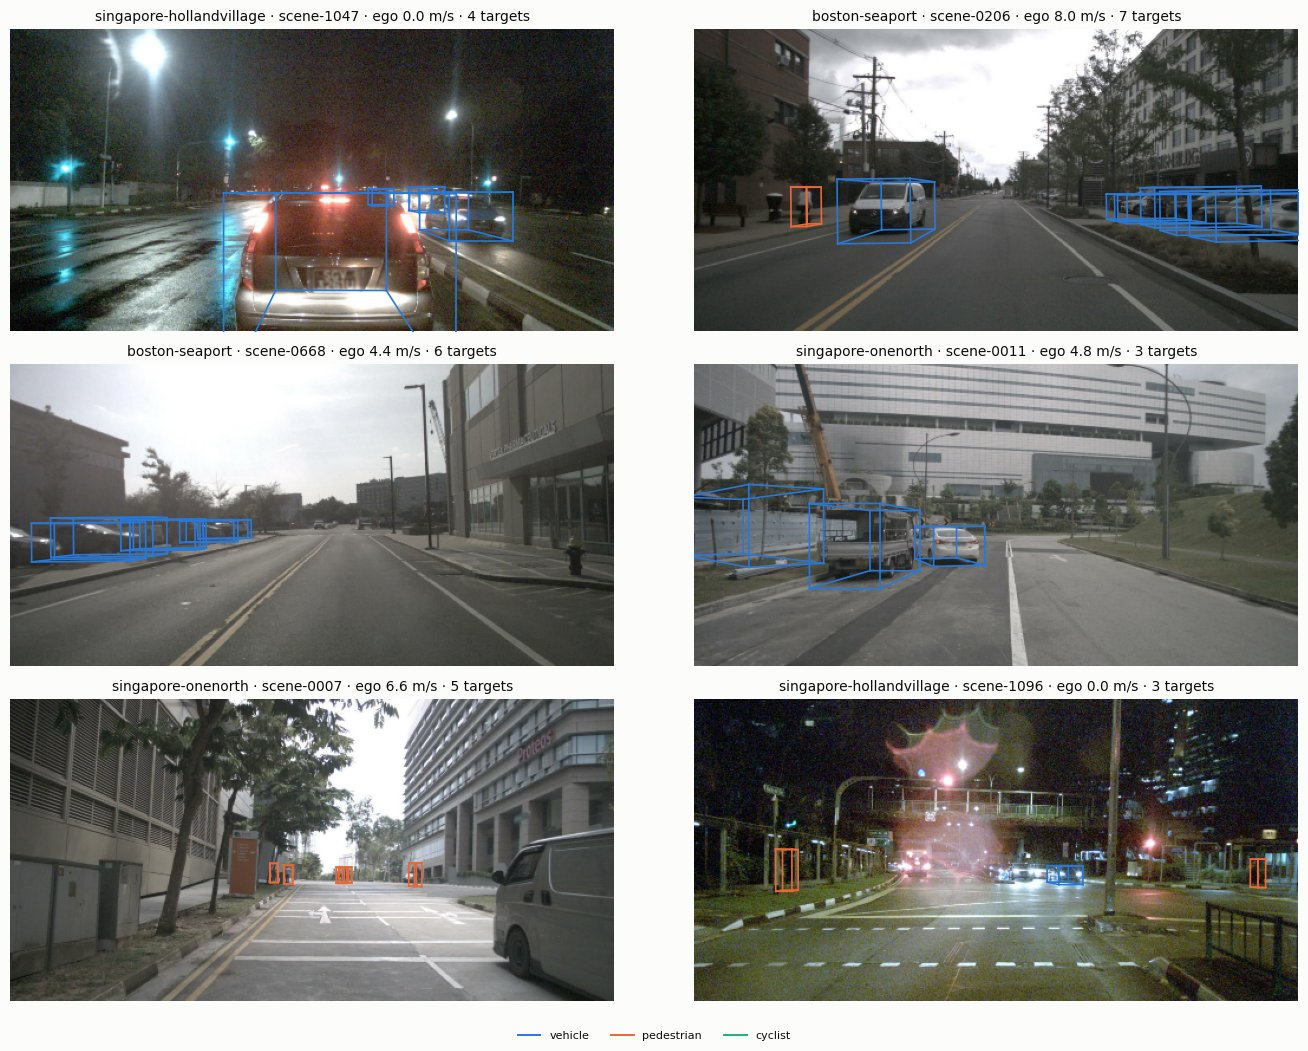

In [8]:
tick_of_row = {i: t for i, t in enumerate(ticks)}
rng = np.random.default_rng(2)
picked, used = [], {}
for r in rng.permutation(rows):
    location = scenes[scene_of_row[r]]["location"]
    if used.get(location, 0) >= 2 or targets_of(r)["mask"].sum() < 3:
        continue
    picked.append(r)
    used[location] = used.get(location, 0) + 1
    if len(picked) == 6:
        break


def image_of(row):
    tick = tick_of_row[row]
    frame = scenes[tick["scene"]]["keyframes"][tick["keyframe"]]
    return views.read_image(NUSC / frame["file"])


fig, axes = plt.subplots(3, 2, figsize=(14, 10.5))
for ax, r in zip(axes.ravel(), picked):
    t = targets_of(r)
    ax.imshow(views.model_view(image_of(r)))
    for k in np.flatnonzero(t["mask"]):
        for (u0, v0), (u1, v1) in views.box_edges_2d(proj[r].astype(np.float64), t["box"][k][None])[0]:
            ax.plot([u0, u1], [v0, v1], color=views.CLASS_COLOURS[t["cls"][k]], lw=1.2)
    ax.set_xlim(0, 512)
    ax.set_ylim(256, 0)
    ax.axis("off")
    tick = tick_of_row[r]
    ax.set_title(f"{scenes[tick['scene']]['location']} · {tick['scene']} · ego {tick['speed']:.1f} m/s · {int(t['mask'].sum())} targets")
fig.legend(handles=[plt.Line2D([], [], color=c, lw=1.4, label=n) for n, c in zip(views.CLASS_NAMES, views.CLASS_COLOURS)],
           loc="lower center", ncol=3)
plt.tight_layout(rect=(0, 0.03, 1, 1))
views.show_jpeg(fig)

**One of them from above**, with every labelled agent (grey: not a target), the targets' velocity arrows
(1 s) and their positions at +0.5 s and +1.0 s, against the camera's view.

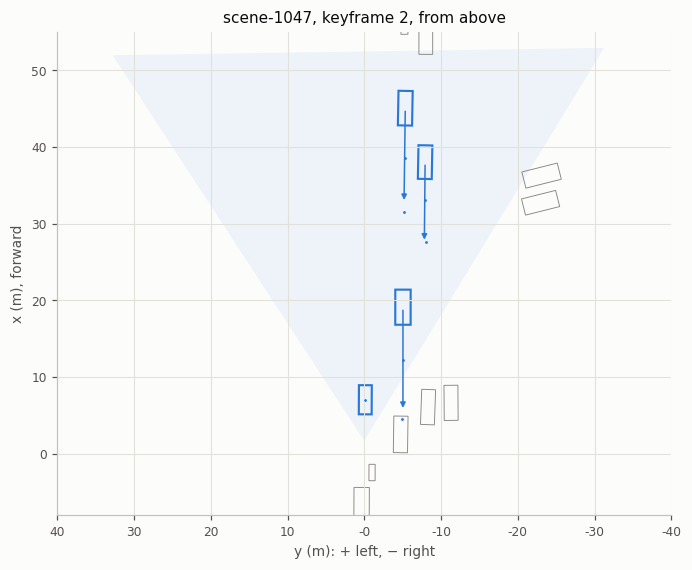

In [9]:
r = picked[0]
agents = navsim_data.agents_of(labels, r)
t = targets_of(r)
fig, ax = plt.subplots(figsize=(7.2, 6.4))
edges = views.view_edges(proj[r].astype(np.float64), reach=60)
ax.add_patch(Polygon(np.c_[-edges[:, 1], edges[:, 0]], closed=True, color="#86b6ef", alpha=0.12, lw=0))
target_xy = t["box"][t["mask"], :2]
for k in range(len(agents["cls"])):
    if agents["cls"][k] < 3 and np.any(np.all(np.isclose(target_xy, agents["box"][k, :2]), axis=1)):
        continue
    outline = views.footprint(agents["box"][k][None])[0]
    ax.add_patch(Polygon(np.c_[-outline[:, 1], outline[:, 0]], closed=True, fill=False, ec=views.GREY, lw=0.6))
for k in np.flatnonzero(t["mask"]):
    colour = views.CLASS_COLOURS[t["cls"][k]]
    outline = views.footprint(t["box"][k][None])[0]
    ax.add_patch(Polygon(np.c_[-outline[:, 1], outline[:, 0]], closed=True, fill=False, ec=colour, lw=1.4))
    x, y = t["box"][k, :2]
    vx, vy = t["vel"][k]
    if np.hypot(vx, vy) > 0.3:
        ax.annotate("", xy=(-(y + vy), x + vx), xytext=(-y, x), arrowprops=dict(arrowstyle="-|>", color=colour, lw=1.0, mutation_scale=7))
    pts = (t["box"][k, None, :2] + t["path"][k])[t["path_ok"][k]]
    ax.plot(-pts[:, 1], pts[:, 0], "o", ms=2.5, color=colour, mec=views.SURFACE, mew=0.6)
ax.set_xlim(-40, 40)
ax.set_ylim(-8, 55)
ax.set_aspect("equal")
y_axis_left(ax)
ax.set_title(f"{tick_of_row[r]['scene']}, keyframe {tick_of_row[r]['keyframe']}, from above")
plt.show()

## 6. What is ready, and what step 7 still does

**Ready** (`{runs}/drivejepa_perception/`, recipe stages `ood-train-scenes`, `ood-draw`, `ood-extract`,
`ood-pass`):
- `nusc-train-scenes.json` and the committed draw;
- `nusc-extract/`: the drawn scenes' keyframes, poses, calibration, annotations and scene descriptions;
- `nusc-v1/`: per kept keyframe, the ViT's output (the side-car's input, 512 × 1024 fp16), the camera
  geometry, and the labels in H15's layout; plus the release's own outputs, which Part A does not read.

**Step 7 still does**, after step 6: a side-car-only readout on these keyframes (every §8.1 metric, per
class, range and location, night and rain apart), with the variant and epoch step 5 chose. Nothing in this
notebook reads a model.